# Advanced Exploratory Data Analysis (EDA) - Colab Standalone
This notebook performs EDA directly on Colab without needing local `src` files.

In [1]:
# 1. Install Dependencies
!pip install roboflow seaborn pandas matplotlib opencv-python -q

In [2]:
# 2. Download Dataset from Roboflow
from roboflow import Roboflow
import os

rf = Roboflow(api_key="rkk8UgicFLnBv2uW8xrc")
project = rf.workspace("nareks-workspace-gfmp5").project("military-vehicles-detection-qwfnc-8qvf8")
version = project.version(1)
dataset = version.download("yolov8")

DATASET_DIR = "/content/Military-vehicles-detection-1"

loading Roboflow workspace...
loading Roboflow project...


In [3]:
# 3. Parse Labels into DataFrame
import pandas as pd
import yaml

with open(f"{DATASET_DIR}/data.yaml", 'r') as f:
    data_yaml = yaml.safe_load(f)

if isinstance(data_yaml['names'], dict):
    class_names = data_yaml['names']
else:
    class_names = {i: name for i, name in enumerate(data_yaml['names'])}

data_records = []
for split in ['train', 'valid', 'test']:
    label_dir = os.path.join(DATASET_DIR, split, 'labels')
    if not os.path.exists(label_dir): continue
    for filename in os.listdir(label_dir):
        if not filename.endswith('.txt'): continue
        with open(os.path.join(label_dir, filename), 'r') as f:
            for line in f.readlines():
                parts = line.strip().split()
                if not parts: continue
                class_id = int(parts[0])
                data_records.append({
                    'split': split,
                    'image_id': filename.replace('.txt', ''),
                    'class_id': class_id,
                    'class_name': class_names.get(class_id, f"Unknown_{class_id}"),
                    'x_center': float(parts[1]),
                    'y_center': float(parts[2]),
                    'width': float(parts[3]),
                    'height': float(parts[4])
                })

df = pd.DataFrame(data_records)
df.head()

,split,image_id,class_id,class_name,x_center,y_center,width,height
0,train,frame_000000002839_PNG.rf.d630b18d8103bb7ffbe0...,3,PERSON,0.475825,0.442888,0.012972,0.028017
1,train,frame_000000002839_PNG.rf.d630b18d8103bb7ffbe0...,3,PERSON,0.502358,0.440733,0.012972,0.025862
2,train,frame_000000002839_PNG.rf.d630b18d8103bb7ffbe0...,3,PERSON,0.541274,0.428879,0.012972,0.019397
3,train,frame_000000005971_jpeg.rf.0d33d552c1245d8531c...,1,CIVILIAN_CAR,0.466071,0.978426,0.019286,0.040609
4,train,frame_000000005971_jpeg.rf.0d33d552c1245d8531c...,1,CIVILIAN_CAR,0.497857,0.979061,0.018571,0.039340




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



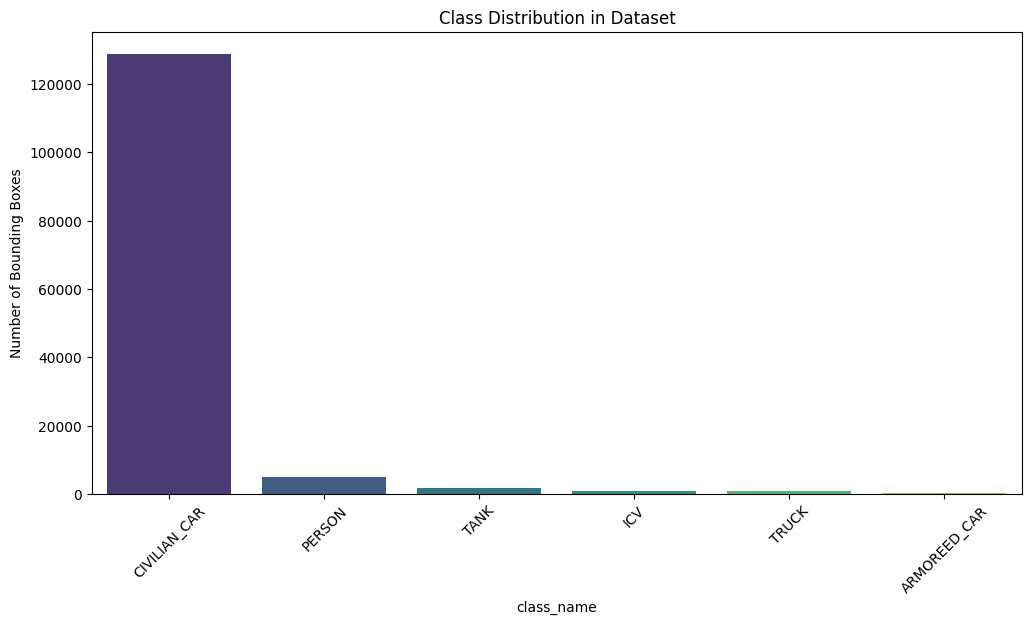

In [4]:
# 4. Visualize Class Imbalance
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='class_name', order=df['class_name'].value_counts().index, palette='viridis')
plt.title("Class Distribution in Dataset")
plt.xticks(rotation=45)
plt.ylabel("Number of Bounding Boxes")
plt.show()

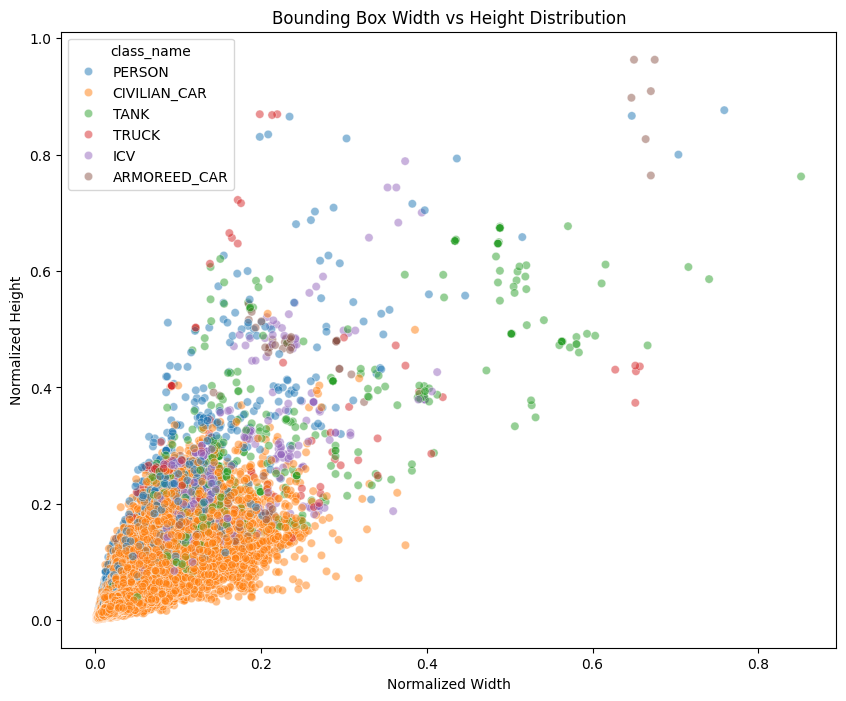

In [5]:
# 5. Visualize Bounding Box Geometry
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df, x='width', y='height', hue='class_name', alpha=0.5)
plt.title("Bounding Box Width vs Height Distribution")
plt.xlabel("Normalized Width")
plt.ylabel("Normalized Height")
plt.show()

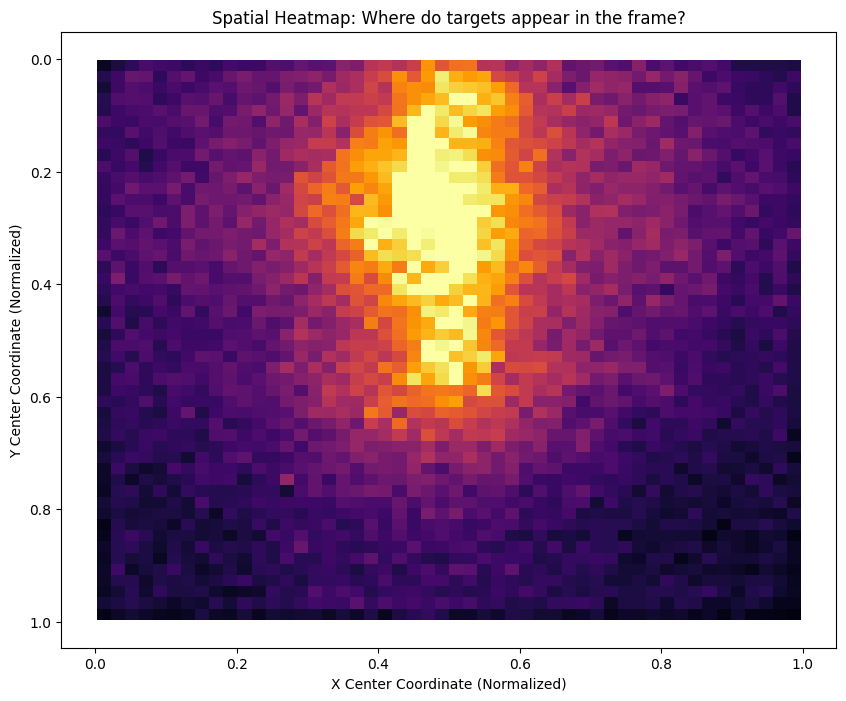

In [8]:
# 6. Spatial Heatmap of Object Locations (Optimized for Speed)
plt.figure(figsize=(10, 8))
sns.histplot(
    data=df, x="x_center", y="y_center",
    bins=50, cmap="inferno", pmax=0.9
)
plt.title("Spatial Heatmap: Where do targets appear in the frame?")
plt.xlabel("X Center Coordinate (Normalized)")
plt.ylabel("Y Center Coordinate (Normalized)")
# Invert Y axis because image coordinates start (0,0) at top-left
plt.gca().invert_yaxis()
plt.show()

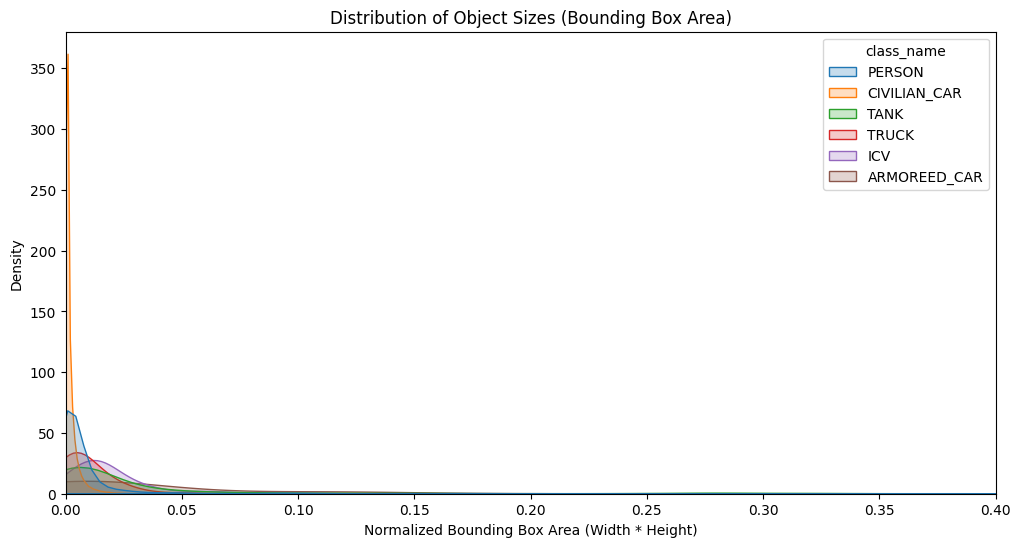

In [6]:
# 7. Distribution of Object Sizes (Area)
df['box_area'] = df['width'] * df['height']

plt.figure(figsize=(12, 6))
sns.kdeplot(data=df, x='box_area', hue='class_name', fill=True, common_norm=False, palette='tab10')
plt.title("Distribution of Object Sizes (Bounding Box Area)")
plt.xlabel("Normalized Bounding Box Area (Width * Height)")
plt.ylabel("Density")
plt.xlim(0, 0.4) # Limiting X axis to zoom in on the majority of objects
plt.show()

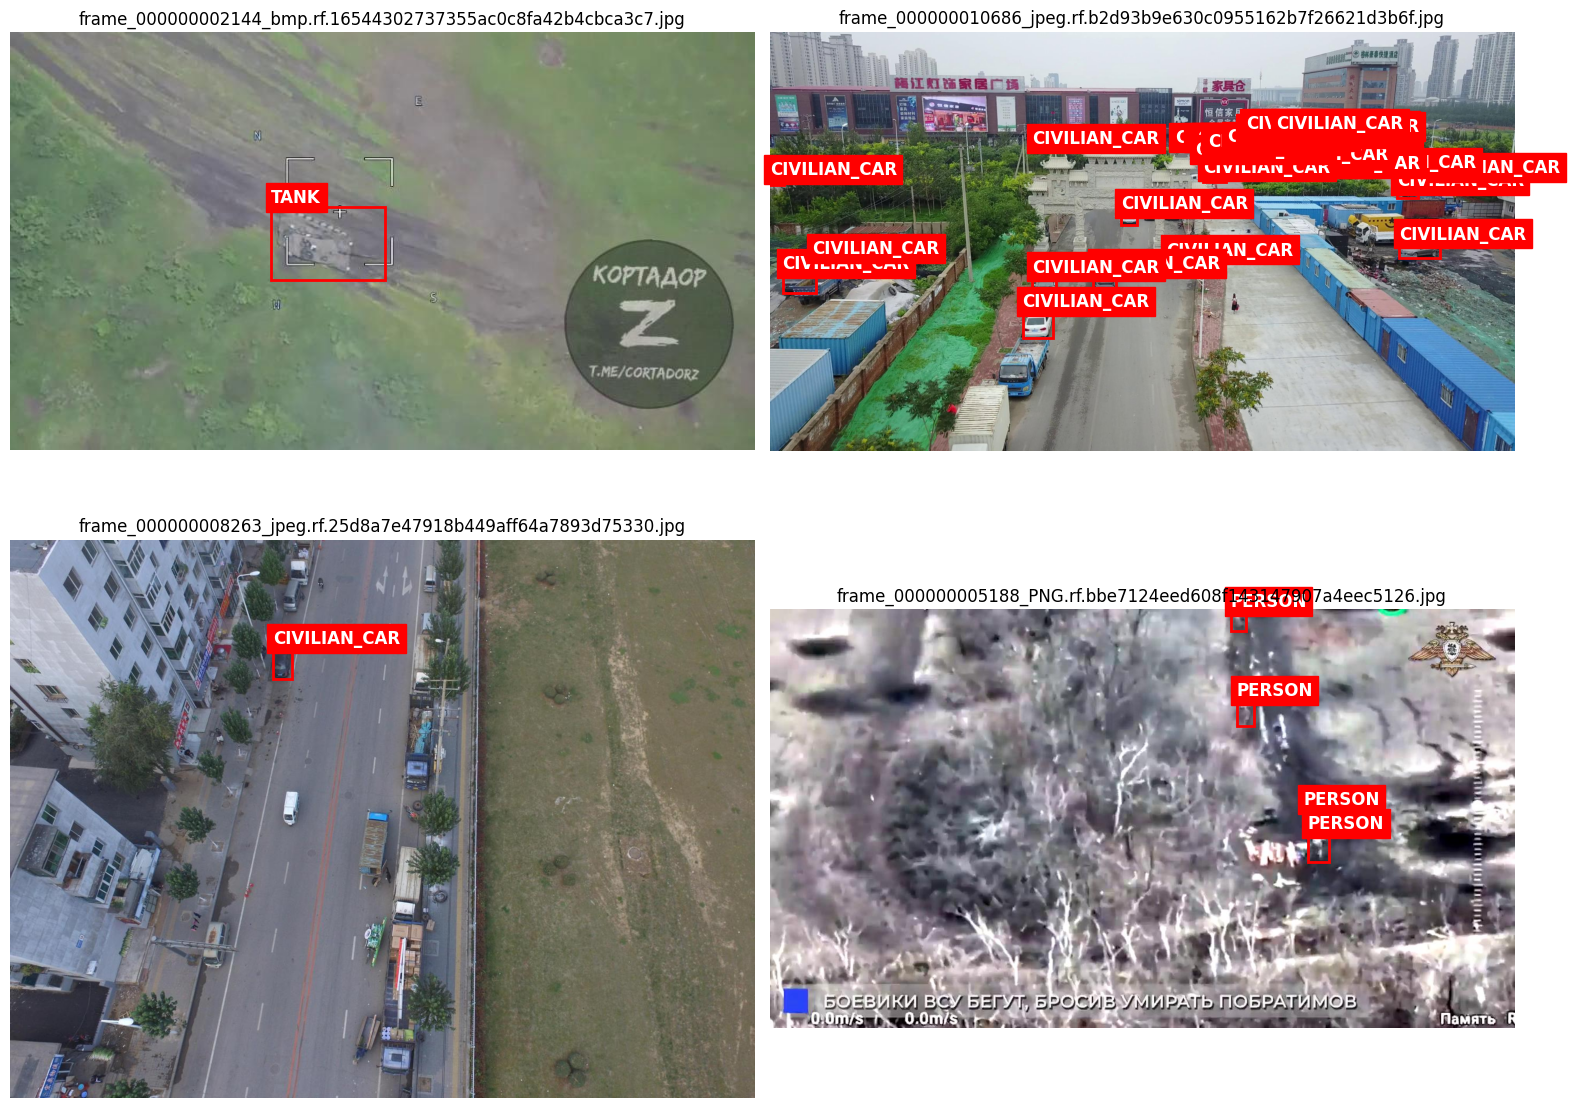

In [7]:
# 8. Visualize Actual Images with Bounding Boxes
import cv2
import random
import matplotlib.patches as patches

# Pick 4 random images from the training set
train_images_dir = f"{DATASET_DIR}/train/images"
train_labels_dir = f"{DATASET_DIR}/train/labels"
sample_images = random.sample([f for f in os.listdir(train_images_dir) if f.endswith('.jpg')], 4)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, img_name in enumerate(sample_images):
    # Load Image
    img_path = os.path.join(train_images_dir, img_name)
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(img_name)

    # Load corresponding label
    label_path = os.path.join(train_labels_dir, img_name.replace('.jpg', '.txt'))
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f.readlines():
                parts = line.strip().split()
                if not parts: continue
                class_id = int(parts[0])
                c_name = class_names.get(class_id, "Unknown")
                x_center, y_center, width, height = map(float, parts[1:5])

                # Convert normalized YOLO coordinates to actual pixel coordinates
                box_w = width * w
                box_h = height * h
                box_x = (x_center * w) - (box_w / 2)
                box_y = (y_center * h) - (box_h / 2)

                # Draw Box
                rect = patches.Rectangle((box_x, box_y), box_w, box_h, linewidth=2, edgecolor='red', facecolor='none')
                axes[i].add_patch(rect)
                axes[i].text(box_x, box_y - 5, c_name, color='white', fontsize=12, backgroundcolor='red', fontweight='bold')

plt.tight_layout()
plt.show()